# Denoiser Benchmarks

Compare MRax denoisers on synthetic 2D and 3D data. Optional BM3D/BM4D backends are included when installed; the notebook runs with MRax's built-in denoisers alone.


In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import time


from mrax.preprocessing import denoise_filter, regularized_denoise

# Optional external backends
try:
    from bm3d import bm3d as bm3d_fn
    HAS_BM3D = True
except Exception:
    bm3d_fn = None
    HAS_BM3D = False

try:
    from bm4d import bm4d as bm4d_fn
    HAS_BM4D = True
except Exception:
    bm4d_fn = None
    HAS_BM4D = False

try:
    from skimage.metrics import structural_similarity as ssim_fn
    HAS_SSIM = True
except Exception:
    ssim_fn = None
    HAS_SSIM = False

rng = np.random.default_rng(0)
timings = {}
metrics_2d = {}
metrics_3d = {}


In [2]:
# Synthetic 2D and 3D data
base2d = np.zeros((64, 64), dtype=float)
base2d[16:48, 16:48] = 1.0
noisy2d = base2d + 0.05 * rng.standard_normal(base2d.shape)

base3d = np.stack([base2d for _ in range(16)], axis=0)
noisy3d = base3d + 0.05 * rng.standard_normal(base3d.shape)


In [3]:
def mse(a, b):
    a = np.asarray(a)
    b = np.asarray(b)
    return float(np.mean((a - b) ** 2))

def psnr(a, b, data_range=1.0):
    val = mse(a, b)
    if val <= 0:
        return float("inf")
    return float(20 * np.log10(float(data_range)) - 10 * np.log10(val))

def ssim_or_nan(a, b):
    if not HAS_SSIM:
        return float("nan")
    a = np.asarray(a)
    b = np.asarray(b)
    return float(ssim_fn(a, b, data_range=float(np.max(a) - np.min(a))))


In [4]:
# Internal denoisers (2D)
t0 = time.perf_counter()
gauss2d = denoise_filter(noisy2d, method="gaussian", sigma=1.2)
timings["gaussian"] = time.perf_counter() - t0

t0 = time.perf_counter()
tv2d = regularized_denoise(
    noisy2d,
    regularizer="tv",
    weight=0.15,
    num_steps=40,
    step_size=0.2,
    optimizer_name="split_bregman",
)
timings["tv_split_bregman"] = time.perf_counter() - t0

results_2d = {
    "gaussian": np.asarray(gauss2d),
    "tv_split_bregman": np.asarray(tv2d),
}

if HAS_BM3D:
    t0 = time.perf_counter()
    bm3d2d = bm3d_fn(noisy2d, sigma_psd=0.05)
    timings["bm3d"] = time.perf_counter() - t0
    results_2d["bm3d"] = np.asarray(bm3d2d)

for name, out in results_2d.items():
    metrics_2d[name] = {
        "mse": mse(base2d, out),
        "psnr": psnr(base2d, out, data_range=1.0),
        "ssim": ssim_or_nan(base2d, out),
    }


In [5]:
# Internal denoisers (3D)
t0 = time.perf_counter()
gauss3d = denoise_filter(noisy3d, method="gaussian", sigma=1.2)
timings["gaussian_3d"] = time.perf_counter() - t0

t0 = time.perf_counter()
tv3d = regularized_denoise(
    noisy3d,
    regularizer="tv",
    weight=0.12,
    num_steps=30,
    step_size=0.2,
    optimizer_name="split_bregman",
)
timings["tv_split_bregman_3d"] = time.perf_counter() - t0

results_3d = {
    "gaussian": np.asarray(gauss3d),
    "tv_split_bregman": np.asarray(tv3d),
}

if HAS_BM4D:
    t0 = time.perf_counter()
    bm4d3d = bm4d_fn(noisy3d, sigma_psd=0.05)
    timings["bm4d"] = time.perf_counter() - t0
    results_3d["bm4d"] = np.asarray(bm4d3d)

for name, out in results_3d.items():
    metrics_3d[name] = {
        "mse": mse(base3d, out),
        "psnr": psnr(base3d, out, data_range=1.0),
    }


In [6]:
# Summary tables
print("2D metrics")
for name, stats in metrics_2d.items():
    print(f"{name:>16s} | mse={stats["mse"]:.4e} psnr={stats["psnr"]:.2f} ssim={stats["ssim"]:.3f}")

print("\n3D metrics")
for name, stats in metrics_3d.items():
    print(f"{name:>16s} | mse={stats["mse"]:.4e} psnr={stats["psnr"]:.2f}")

print("\nTimings (seconds)")
for name, val in timings.items():
    print(f"{name:>22s}: {val:.3f}")


2D metrics
        gaussian | mse=7.7162e-03 psnr=21.13 ssim=0.687
tv_split_bregman | mse=7.3932e-04 psnr=31.31 ssim=0.692
            bm3d | mse=8.8021e-06 psnr=50.55 ssim=0.982

3D metrics
        gaussian | mse=7.6610e-03 psnr=21.16
tv_split_bregman | mse=8.6451e-04 psnr=30.63
            bm4d | mse=5.4343e-06 psnr=52.65

Timings (seconds)
              gaussian: 0.411
      tv_split_bregman: 1.458
                  bm3d: 0.247
           gaussian_3d: 0.468
   tv_split_bregman_3d: 1.376
                  bm4d: 1.342


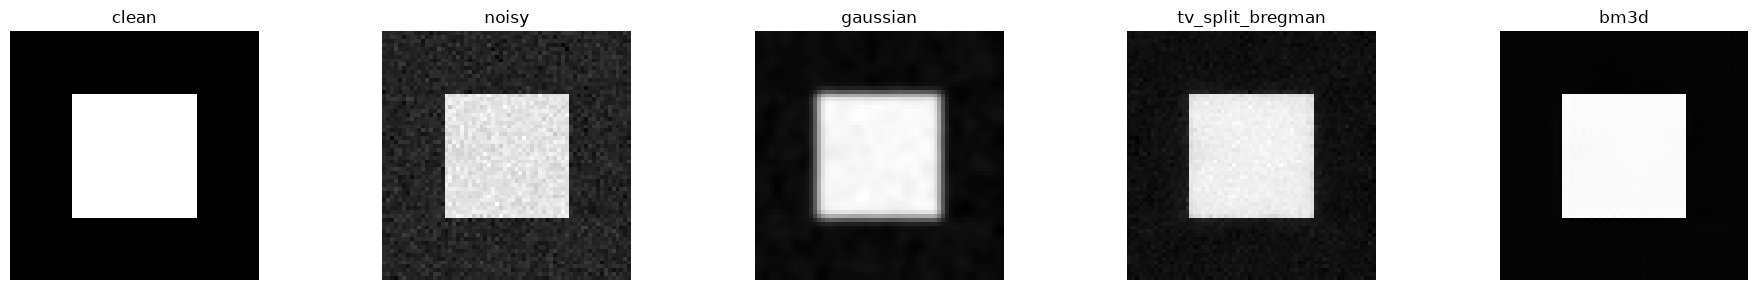

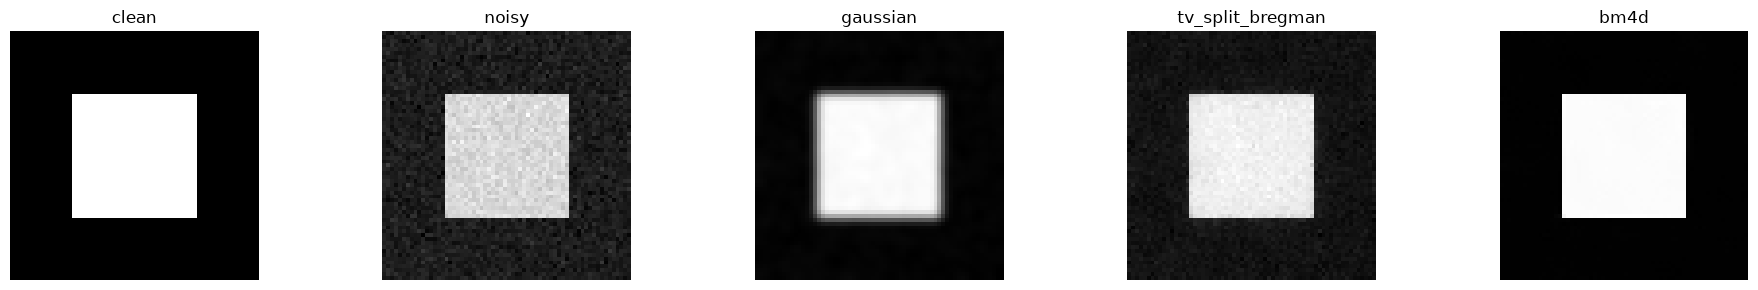

In [7]:
# Visual comparison (2D)
methods = ["gaussian", "tv_split_bregman"] + (["bm3d"] if HAS_BM3D else [])
fig, axes = plt.subplots(1, 2 + len(methods), figsize=(4 + 3 * (2 + len(methods)), 3))
axes[0].imshow(base2d, cmap="gray")
axes[0].set_title("clean")
axes[1].imshow(noisy2d, cmap="gray")
axes[1].set_title("noisy")
for idx, name in enumerate(methods, start=2):
    axes[idx].imshow(results_2d[name], cmap="gray")
    axes[idx].set_title(name)
for ax in axes:
    ax.axis("off")
plt.tight_layout()

# Visual comparison (3D)
slice_idx = base3d.shape[0] // 2
methods3 = ["gaussian", "tv_split_bregman"] + (["bm4d"] if HAS_BM4D else [])
fig, axes = plt.subplots(1, 2 + len(methods3), figsize=(4 + 3 * (2 + len(methods3)), 3))
axes[0].imshow(base3d[slice_idx], cmap="gray")
axes[0].set_title("clean")
axes[1].imshow(noisy3d[slice_idx], cmap="gray")
axes[1].set_title("noisy")
for idx, name in enumerate(methods3, start=2):
    axes[idx].imshow(results_3d[name][slice_idx], cmap="gray")
    axes[idx].set_title(name)
for ax in axes:
    ax.axis("off")
plt.tight_layout()


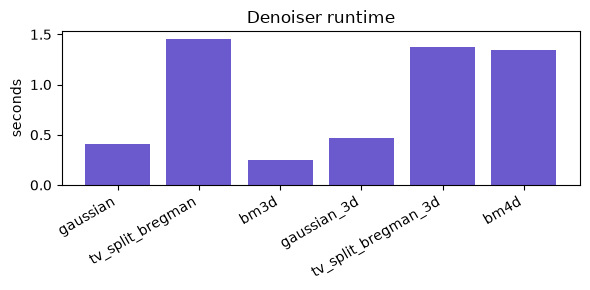

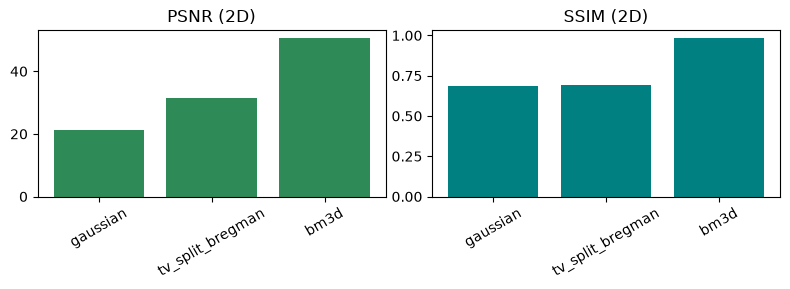

In [8]:
# Timing and metric plots
if timings:
    labels = list(timings.keys())
    values = [timings[k] for k in labels]
    plt.figure(figsize=(6, 3))
    plt.bar(labels, values, color="slateblue")
    plt.ylabel("seconds")
    plt.title("Denoiser runtime")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()

if metrics_2d:
    labels = list(metrics_2d.keys())
    psnr_vals = [metrics_2d[k]["psnr"] for k in labels]
    ssim_vals = [metrics_2d[k]["ssim"] for k in labels]
    fig, axes = plt.subplots(1, 2, figsize=(8, 3))
    axes[0].bar(labels, psnr_vals, color="seagreen")
    axes[0].set_title("PSNR (2D)")
    axes[0].tick_params(axis="x", rotation=30)
    axes[1].bar(labels, ssim_vals, color="teal")
    axes[1].set_title("SSIM (2D)")
    axes[1].tick_params(axis="x", rotation=30)
    fig.tight_layout()


## Notes

- External backends (BM3D/BM4D) require additional packages.
- SSIM is reported when scikit-image is installed; otherwise it is NaN.
